In [2]:
%pip -q install 'cebra==0.6.1' pandas numpy scipy scikit-learn matplotlib requests tqdm

In [3]:
import io, zipfile, time, random
import requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, cebra
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tqdm.auto import tqdm

SEED = 42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
print('CEBRA:', getattr(cebra, '__version__', 'unknown'))

SYMBOL, INTERVAL = 'BTCUSDT', '1h'
START_MONTH, END_MONTH = '2022-01', '2026-10'  # adjust here if desired
WINDOW_HOURS = 168   # 7 days of hourly log returns
HORIZON_HOURS = 168  # predict a 7-day future holding return
TRAIN_END = pd.Timestamp('2025-01-01', tz='UTC')
VAL_END = pd.Timestamp('2026-01-01', tz='UTC')

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.14.1+cu130 | CUDA available: True
CEBRA: 0.6.1


In [4]:
def fetch_month(year_month, session):
    url = (f'https://data.binance.vision/data/spot/monthly/klines/'
           f'{SYMBOL}/{INTERVAL}/{SYMBOL}-{INTERVAL}-{year_month}.zip')
    for attempt in range(4):
        try:
            res = session.get(url, timeout=45)
            res.raise_for_status()
            with zipfile.ZipFile(io.BytesIO(res.content)) as z:
                fname = next(x for x in z.namelist() if x.endswith('.csv'))
                with z.open(fname) as f:
                    frame = pd.read_csv(f, header=None, usecols=[0, 4])
            frame.columns = ['open_time', 'close']
            return frame
        except (requests.RequestException, zipfile.BadZipFile) as e:
            if attempt == 3:
                raise RuntimeError(f'Archive failed: {url} ({e})') from e
            time.sleep(1.5 * (attempt + 1))

months = pd.period_range(START_MONTH, END_MONTH, freq='M')
with requests.Session() as session:
    frames = [fetch_month(str(m), session) for m in tqdm(months, desc='Monthly archives')]
df = pd.concat(frames, ignore_index=True)
df['open_time'] = pd.to_numeric(df['open_time'], errors='coerce')
df['close'] = pd.to_numeric(df['close'], errors='coerce')
df = df.dropna(subset=['open_time', 'close']).copy()
raw_ts = df['open_time'].astype('int64').to_numpy()
ms = np.where(raw_ts >= 10**14, raw_ts // 1000, raw_ts)
df['time_utc'] = pd.to_datetime(ms, unit='ms', utc=True)
df = (df[['time_utc', 'close']]
      .drop_duplicates('time_utc')
      .sort_values('time_utc').reset_index(drop=True))
assert (df.close > 0).all()
print(f'Rows: {len(df):,}, from {df.time_utc.min()} to {df.time_utc.max()}')
print('Missing hourly timestamps in range:',
      len(pd.date_range(df.time_utc.min(), df.time_utc.max(), freq='h')) - len(df))
display(df.head(), df.tail())

Monthly archives:   0%|          | 0/58 [00:00<?, ?it/s]

Rows: 42,359, from 2022-01-01 00:00:00+00:00 to 2026-10-31 23:00:00+00:00
Missing hourly timestamps in range: 1


,time_utc,close
0,2022-01-01 00:00:00+00:00,46656.13
1,2022-01-01 01:00:00+00:00,46778.14
2,2022-01-01 02:00:00+00:00,46811.77
3,2022-01-01 03:00:00+00:00,46813.20
4,2022-01-01 04:00:00+00:00,46711.05


,time_utc,close
42354,2026-10-31 19:00:00+00:00,77588.83
42355,2026-10-31 20:00:00+00:00,77565.87
42356,2026-10-31 21:00:00+00:00,77682.01
42357,2026-10-31 22:00:00+00:00,77548.01
42358,2026-10-31 23:00:00+00:00,77582.02


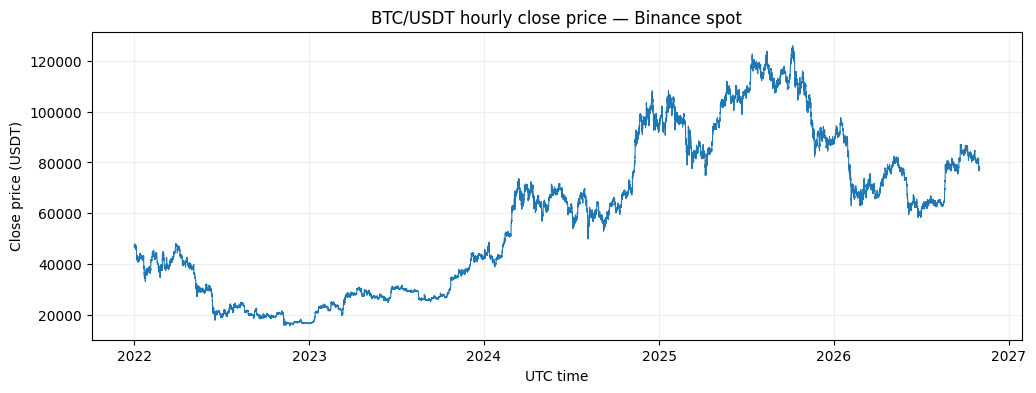

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.time_utc, df.close, lw=0.8)
ax.set(title='BTC/USDT hourly close price — Binance spot', xlabel='UTC time', ylabel='Close price (USDT)')
ax.grid(alpha=0.2)
plt.show()

In [6]:
from numpy.lib.stride_tricks import sliding_window_view

prices = df.close.to_numpy(dtype=np.float64)
log_returns = np.diff(np.log(prices), prepend=np.log(prices[0]))
timestamps = df.time_utc.to_numpy(dtype='datetime64[ns]')

n = len(df)
end_idx = np.arange(WINDOW_HOURS - 1, n - HORIZON_HOURS - 1, dtype=np.int64)
X_all = sliding_window_view(log_returns, WINDOW_HOURS)[end_idx - WINDOW_HOURS + 1].copy().astype('float32')
y_all = (prices[end_idx + HORIZON_HOURS + 1] / prices[end_idx + 1] - 1).astype('float64')
signal_dates = pd.DatetimeIndex(df.time_utc.iloc[end_idx])
target_end_dates = pd.DatetimeIndex(df.time_utc.iloc[end_idx + HORIZON_HOURS + 1])

# A complete contiguous window contains WINDOW_HOURS + HORIZON_HOURS elapsed hours.
valid_clock = ((timestamps[end_idx + HORIZON_HOURS + 1]
                - timestamps[end_idx - WINDOW_HOURS + 1])
               == np.timedelta64(WINDOW_HOURS + HORIZON_HOURS, 'h'))
end_idx = end_idx[valid_clock]
X_all, y_all = X_all[valid_clock], y_all[valid_clock]
signal_dates = signal_dates[valid_clock]
target_end_dates = target_end_dates[valid_clock]

train_mask = target_end_dates < TRAIN_END
val_mask = (signal_dates >= TRAIN_END) & (target_end_dates < VAL_END)
test_mask = signal_dates >= VAL_END
assert train_mask.sum() > 1000 and val_mask.sum() > 1000 and test_mask.sum() > 1000
assert not np.any(train_mask & val_mask) and not np.any(val_mask & test_mask)

scaler = StandardScaler().fit(X_all[train_mask])
X = scaler.transform(X_all).astype('float32')
print('Samples: train:', train_mask.sum(), 'val:', val_mask.sum(), 'test:', test_mask.sum())
print('Feature shape:', X.shape, 'Target shape:', y_all.shape)
print('Train max label time:', target_end_dates[train_mask].max())
print('Validation max label time:', target_end_dates[val_mask].max())
print('Test signal range:', signal_dates[test_mask].min(), '→', signal_dates[test_mask].max())

Samples: train: 25631 val: 8591 test: 7127
Feature shape: (41687, 168) Target shape: (41687,)
Train max label time: 2024-12-31 23:00:00+00:00
Validation max label time: 2025-12-31 23:00:00+00:00
Test signal range: 2026-01-01 00:00:00+00:00 → 2026-10-24 22:00:00+00:00


In [7]:
# Ridge baseline (same observations and target as CEBRA)
raw_head = Ridge(alpha=100.0).fit(X[train_mask], y_all[train_mask])
raw_preds = raw_head.predict(X)

# CEBRA-Time learns on PRICE-DERIVED INPUTS ONLY; no prediction labels are supplied.
cebra_model = cebra.CEBRA(
    model_architecture='offset1-model',
    conditional='time',
    time_offsets=10,
    batch_size=512,
    learning_rate=1e-3,
    output_dimension=8,
    max_iterations=1000,
    device='cuda_if_available',
    verbose=False,
)
cebra_model.fit(X[train_mask])

# Transform using trained encoder (no fitting / adaptation on test)
Z = cebra_model.transform(X)
assert len(Z) == len(y_all), 'Embedding size mismatch'
cebra_head = Ridge(alpha=10.0).fit(Z[train_mask], y_all[train_mask])
cebra_preds = cebra_head.predict(Z)
print('CEBRA latent shape:', Z.shape)

CEBRA latent shape: (41687, 8)


Independent weekly decisions | val: 52 | test: 43
VALIDATION:


,n_weeks,MAE,RMSE,R2,Direction_Accuracy
model,,,,,
Zero forecast,52,0.040122,0.050163,-0.000019,0.5
Ridge (price only),52,0.040877,0.050486,-0.012973,0.5
CEBRA-Time + Ridge,52,0.040752,0.051002,-0.033763,0.5


TEST:


,n_weeks,MAE,RMSE,R2,Direction_Accuracy
model,,,,,
Zero forecast,43,0.042970,0.058707,-0.000050,0.511628
Ridge (price only),43,0.043595,0.059047,-0.011680,0.488372
CEBRA-Time + Ridge,43,0.044434,0.059827,-0.038595,0.488372


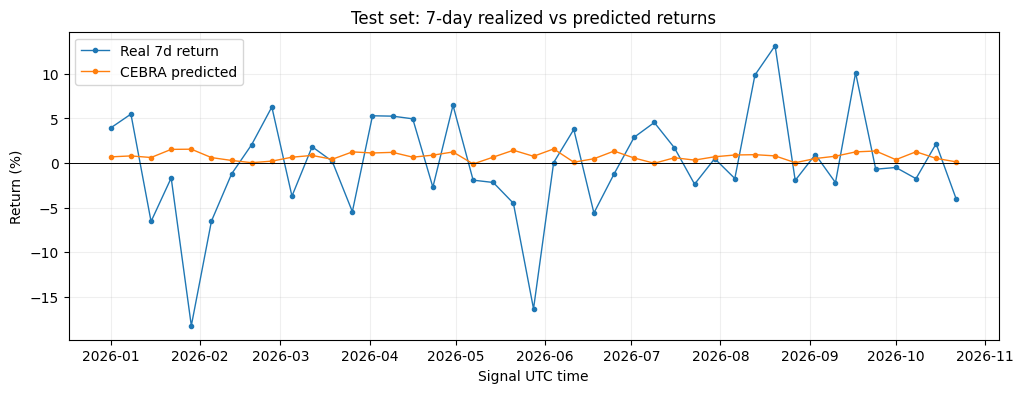

In [8]:
def weekly_indices(mask, step=HORIZON_HOURS):
    # Weekly signal times are at least 168h apart. Adjacent 168h holds can touch but do not overlap.
    all_idx = np.flatnonzero(mask)
    selected = []
    last_signal = None
    min_spacing = pd.Timedelta(hours=step)
    for i in all_idx:
        if last_signal is None or signal_dates[i] >= last_signal + min_spacing:
            selected.append(i)
            last_signal = signal_dates[i]
    return np.array(selected, dtype=np.int64)

idx_val = weekly_indices(val_mask)
idx_test = weekly_indices(test_mask)
print('Independent weekly decisions | val:', len(idx_val), '| test:', len(idx_test))

def forecast_metrics(idx):
    actual = y_all[idx]
    rows = []
    for name, forecast in [('Zero forecast', np.zeros_like(actual)),
                           ('Ridge (price only)', raw_preds[idx]),
                           ('CEBRA-Time + Ridge', cebra_preds[idx])]:
        rows.append(dict(model=name,
                         n_weeks=len(idx),
                         MAE=mean_absolute_error(actual, forecast),
                         RMSE=np.sqrt(mean_squared_error(actual, forecast)),
                         R2=r2_score(actual, forecast),
                         Direction_Accuracy=np.mean((forecast > 0) == (actual > 0))))
    return pd.DataFrame(rows).set_index('model')

print('VALIDATION:')
display(forecast_metrics(idx_val))
print('TEST:')
display(forecast_metrics(idx_test))

fig, ax = plt.subplots(figsize=(12, 4))
weekly_dates = signal_dates[idx_test]
ax.plot(weekly_dates, 100*y_all[idx_test], 'o-', ms=3, lw=1, label='Real 7d return')
ax.plot(weekly_dates, 100*cebra_preds[idx_test], '.-', lw=1, label='CEBRA predicted')
ax.axhline(0, color='k', lw=0.7)
ax.set(title='Test set: 7-day realized vs predicted returns', xlabel='Signal UTC time', ylabel='Return (%)')
ax.legend(); ax.grid(alpha=0.2)
plt.show()

Validation-selected thresholds: {'Ridge': 0.005, 'CEBRA': 0.02}


,weeks,invested_weeks,total_return,max_drawdown
strategy,,,,
Cash,43,0,0.00%,0.00%
Buy & hold BTC,43,43,-9.30%,-37.61%
Ridge strategy,43,39,-8.17%,-38.13%
CEBRA strategy,43,0,0.00%,0.00%


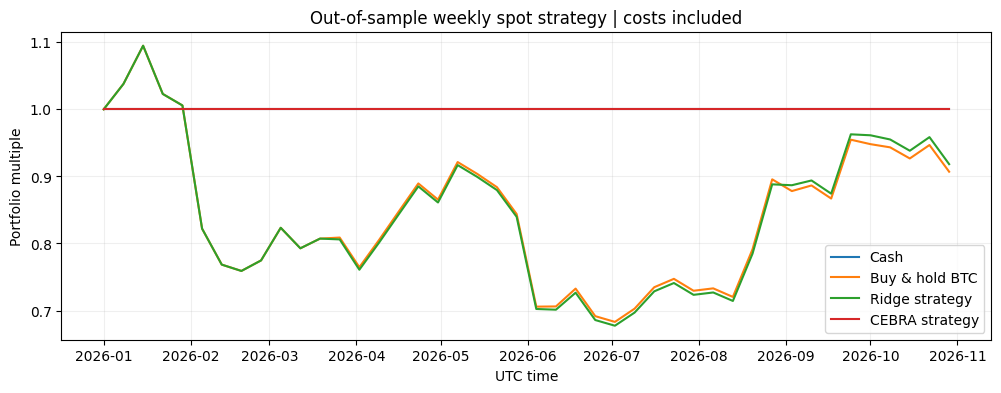

Saved btc_cebra_2026_weekly_predictions.csv


,signal_time_utc,target_end_time_utc,realized_7d_return,ridge_pred_7d_return,cebra_pred_7d_return,cebra_position_BTC
33,2026-08-20 00:00:00+00:00,2026-08-27 01:00:00+00:00,0.131619,0.012279,0.007979,0
34,2026-08-27 00:00:00+00:00,2026-09-03 01:00:00+00:00,-0.019544,0.004963,0.000327,0
35,2026-09-03 00:00:00+00:00,2026-09-10 01:00:00+00:00,0.009531,0.007401,0.005020,0
36,2026-09-10 00:00:00+00:00,2026-09-17 01:00:00+00:00,-0.022022,0.008076,0.007623,0
37,2026-09-17 00:00:00+00:00,2026-09-24 01:00:00+00:00,0.101214,0.008388,0.012463,0
38,2026-09-24 00:00:00+00:00,2026-10-01 01:00:00+00:00,-0.006971,0.004863,0.013468,0
39,2026-10-01 00:00:00+00:00,2026-10-08 01:00:00+00:00,-0.005015,0.007885,0.003744,0
40,2026-10-08 00:00:00+00:00,2026-10-15 01:00:00+00:00,-0.017560,0.006778,0.012613,0
41,2026-10-15 00:00:00+00:00,2026-10-22 01:00:00+00:00,0.021603,0.005525,0.005157,0
42,2026-10-22 00:00:00+00:00,2026-10-29 01:00:00+00:00,-0.040575,0.009220,0.001283,0


In [9]:
ONE_WAY_COST = 0.0015
THRESHOLDS = [0.0, 0.005, 0.01, 0.02]

def portfolio_curve(idx, positions, one_way_cost=ONE_WAY_COST):
    # Each weekly label has entry at next hourly close and exit 168 hours later.
    # Adjacent weekly intervals do not overlap by construction.
    growth = [1.0]
    prev_position = 0
    for i, pos in zip(idx, positions):
        trade_cost = one_way_cost * abs(int(pos) - prev_position)
        growth.append(growth[-1] * (1 - trade_cost) * (1 + int(pos) * y_all[i]))
        prev_position = int(pos)
    if len(positions) and prev_position:
        growth[-1] *= (1 - one_way_cost)  # final liquidation to cash
    return np.array(growth)

def choose_threshold(idx, preds):
    scores = []
    for threshold in THRESHOLDS:
        positions = (preds[idx] > threshold).astype(int)
        curve = portfolio_curve(idx, positions)
        scores.append((float(curve[-1]), threshold))
    # Deterministic tie-break: smallest threshold.
    return sorted(scores, key=lambda x: (-x[0], x[1]))[0][1]

best_raw = choose_threshold(idx_val, raw_preds)
best_cebra = choose_threshold(idx_val, cebra_preds)
print('Validation-selected thresholds:', {'Ridge': best_raw, 'CEBRA': best_cebra})

positions = {
    'Cash': np.zeros(len(idx_test), dtype=int),
    'Buy & hold BTC': np.ones(len(idx_test), dtype=int),
    'Ridge strategy': (raw_preds[idx_test] > best_raw).astype(int),
    'CEBRA strategy': (cebra_preds[idx_test] > best_cebra).astype(int),
}
curves = {name: portfolio_curve(idx_test, pos) for name, pos in positions.items()}
report = []
for name, curve in curves.items():
    dd = curve / np.maximum.accumulate(curve) - 1.0
    report.append(dict(strategy=name,
                       weeks=len(idx_test),
                       invested_weeks=int(positions[name].sum()),
                       total_return=curve[-1]-1,
                       max_drawdown=dd.min()))
report = pd.DataFrame(report).set_index('strategy')
display(report.style.format({'total_return':'{:.2%}', 'max_drawdown':'{:.2%}'}))

fig, ax = plt.subplots(figsize=(12, 4))
plot_times = [signal_dates[idx_test[0]]] + list(target_end_dates[idx_test])
for name, curve in curves.items():
    ax.plot(plot_times, curve, label=name)
ax.set(title='Out-of-sample weekly spot strategy | costs included',
       xlabel='UTC time', ylabel='Portfolio multiple')
ax.grid(alpha=0.2); ax.legend(); plt.show()

out = pd.DataFrame({
    'signal_time_utc': signal_dates[idx_test],
    'target_end_time_utc': target_end_dates[idx_test],
    'realized_7d_return': y_all[idx_test],
    'ridge_pred_7d_return': raw_preds[idx_test],
    'cebra_pred_7d_return': cebra_preds[idx_test],
    'cebra_position_BTC': positions['CEBRA strategy'],
})
out.to_csv('btc_cebra_2026_weekly_predictions.csv', index=False)
print('Saved btc_cebra_2026_weekly_predictions.csv')
display(out.tail(10))

In [10]:
# NEW CELL 1 — identical sample times for 7/30/60 day input windows
%pip -q install lightgbm
from lightgbm import LGBMRegressor, LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, accuracy_score
from numpy.lib.stride_tricks import sliding_window_view
import gc

XP_WINDOWS = [7*24, 30*24, 60*24]  # input lengths (hours)
XP_HORIZON = 7*24                    # fixed forecast horizon (hours)
XP_MAXWIN = max(XP_WINDOWS)
XP_SEED = 42

# 'end_idx', 'timestamps', 'signal_dates', 'target_end_dates', 'y_all'
# and train/val/test masks were prepared by original cell 4.
# Ensure each 60-day input + 7-day target spans exactly the expected hours:
XP_KEEP = (end_idx >= XP_MAXWIN - 1) & (
    (timestamps[end_idx + HORIZON_HOURS + 1]
     - timestamps[end_idx - XP_MAXWIN + 1])
    == np.timedelta64(XP_MAXWIN + HORIZON_HOURS, 'h')
)
xp_end = end_idx[XP_KEEP]
xp_y = y_all[XP_KEEP]
xp_time = signal_dates[XP_KEEP]
xp_end_time = target_end_dates[XP_KEEP]
xp_train = train_mask[XP_KEEP]
xp_val = val_mask[XP_KEEP]
xp_test = test_mask[XP_KEEP]
assert XP_HORIZON == HORIZON_HOURS
assert xp_train.sum() > 1000 and xp_val.sum() > 1000 and xp_test.sum() > 1000
assert not (xp_train & xp_val).any() and not (xp_val & xp_test).any()

def xp_weekly(mask):
    chosen = []
    last = None
    for i in np.flatnonzero(mask):
        if last is None or xp_time[i] >= last + pd.Timedelta(hours=XP_HORIZON):
            chosen.append(i)
            last = xp_time[i]
    return np.asarray(chosen, dtype=int)

xp_iv = xp_weekly(xp_val)
xp_it = xp_weekly(xp_test)
print('Common samples:', len(xp_y), '| train / val / test:',
      xp_train.sum(), xp_val.sum(), xp_test.sum())
print('Weekly evaluation observations:', 'validation', len(xp_iv), '| test', len(xp_it))
print('Target:', XP_HORIZON, 'hours forward, with entry at the next candle close')


Common samples: 39143 | train / val / test: 23087 8591 7127
Weekly evaluation observations: validation 52 | test 43
Target: 168 hours forward, with entry at the next candle close


In [11]:
# NEW CELL 2 — price-only LightGBM baselines (regression and direction)
# Features are strictly historical: past log returns and realized volatility.
xp_features = {}
for lag in [1, 3, 6, 12, 24, 48, 72, 168, 336, 720, 1440]:
    xp_features[f'logret_{lag}h'] = np.log(prices[xp_end] / prices[xp_end - lag])
for lag in [24, 168, 720]:
    roll_std = pd.Series(log_returns).rolling(lag, min_periods=lag).std().to_numpy()
    xp_features[f'vol_{lag}h'] = roll_std[xp_end]
xp_features = pd.DataFrame(xp_features, index=np.arange(len(xp_y)))
assert np.isfinite(xp_features.to_numpy()).all()

xp_preds = {}        # predicted 7-day return
xp_probs = {}        # predicted probability of an UP week
xp_clf_labels = (xp_y > 0).astype(int)

xp_lgb_reg = LGBMRegressor(n_estimators=250, learning_rate=0.03,
                           num_leaves=15, min_child_samples=100,
                           random_state=XP_SEED, verbosity=-1)
xp_lgb_cls = LGBMClassifier(n_estimators=250, learning_rate=0.03,
                            num_leaves=15, min_child_samples=100,
                            random_state=XP_SEED, verbosity=-1)
xp_lgb_reg.fit(xp_features.loc[xp_train], xp_y[xp_train])
xp_lgb_cls.fit(xp_features.loc[xp_train], xp_clf_labels[xp_train])
xp_preds['LightGBM'] = xp_lgb_reg.predict(xp_features)
xp_probs['LightGBM'] = xp_lgb_cls.predict_proba(xp_features)[:, 1]
print('LightGBM training completed. Predictions only use price history.')


LightGBM training completed. Predictions only use price history.


In [12]:
# NEW CELL 3 — train CEBRA-Time separately with 7/30/60-day histories
# All variants share the exact same dates and 7-day prediction target.
# CPU Colab also works but may be considerably slower. Lower iterations for a quick smoke test only.
XP_ITERATIONS = 800
xp_encoders = {}   # retain fitted transformers/heads for later inference
for window in XP_WINDOWS:
    days = window // 24
    print(f'\n=== CEBRA with {days}-day price history ===', flush=True)
    xw = sliding_window_view(log_returns, window)[xp_end - window + 1].copy().astype('float32')
    sw = StandardScaler().fit(xw[xp_train])  # fit on TRAIN only
    xw = sw.transform(xw).astype('float32')

    np.random.seed(XP_SEED)
    torch.manual_seed(XP_SEED)
    encoder = cebra.CEBRA(
        model_architecture='offset1-model', conditional='time',
        time_offsets=10, batch_size=512, learning_rate=1e-3,
        output_dimension=8, max_iterations=XP_ITERATIONS,
        device='cuda_if_available', verbose=False,
    )
    encoder.fit(xw[xp_train])     # unsupervised TIME-CEBRA, TRAIN only
    zw = encoder.transform(xw)    # features for every period, no refitting
    head_r = Ridge(alpha=10).fit(zw[xp_train], xp_y[xp_train])
    head_c = LogisticRegression(max_iter=500, random_state=XP_SEED).fit(
        zw[xp_train], xp_clf_labels[xp_train]
    )
    xp_preds[f'CEBRA-{days}d'] = head_r.predict(zw)
    xp_probs[f'CEBRA-{days}d'] = head_c.predict_proba(zw)[:, 1]
    xp_encoders[days] = (sw, encoder, head_r, head_c)
    print('Latents:', zw.shape, '| mean prediction (validation):',
          round(float(xp_preds[f'CEBRA-{days}d'][xp_iv].mean()), 5))
    del xw, zw
    gc.collect()
print('\nFinished all CEBRA window experiments.')



=== CEBRA with 7-day price history ===
Latents: (39143, 8) | mean prediction (validation): 0.00974

=== CEBRA with 30-day price history ===
Latents: (39143, 8) | mean prediction (validation): 0.00938

=== CEBRA with 60-day price history ===
Latents: (39143, 8) | mean prediction (validation): 0.01133

Finished all CEBRA window experiments.



--- VALIDATION 2025 | RETURN FORECAST ---


,n,MAE,RMSE,R2,DirectionAcc
model,,,,,
Zero forecast,52,4.012%,5.016%,-0.000,50.0%
LightGBM,52,4.383%,5.867%,-0.368,53.8%
CEBRA-7d,52,4.121%,5.142%,-0.051,50.0%
CEBRA-30d,52,3.868%,4.944%,0.029,48.1%
CEBRA-60d,52,4.074%,5.119%,-0.041,50.0%


--- VALIDATION 2025 | UP/DOWN FORECAST ---


,n,Accuracy,Brier,MeanPredictedUp,ActualUp
model,,,,,
LightGBM,52,53.8%,0.297,49.7%,50.0%
CEBRA-7d,52,50.0%,0.252,53.9%,50.0%
CEBRA-30d,52,53.8%,0.243,53.3%,50.0%
CEBRA-60d,52,57.7%,0.244,53.5%,50.0%



--- EXPLORATORY TEST 2026 | RETURN FORECAST ---


,n,MAE,RMSE,R2,DirectionAcc
model,,,,,
Zero forecast,43,4.297%,5.871%,-0.000,51.2%
LightGBM,43,4.531%,5.961%,-0.031,60.5%
CEBRA-7d,43,4.501%,6.051%,-0.063,48.8%
CEBRA-30d,43,4.575%,6.079%,-0.072,51.2%
CEBRA-60d,43,4.616%,6.062%,-0.066,46.5%


--- EXPLORATORY TEST 2026 | UP/DOWN FORECAST ---


,n,Accuracy,Brier,MeanPredictedUp,ActualUp
model,,,,,
LightGBM,43,69.8%,0.231,51.1%,48.8%
CEBRA-7d,43,48.8%,0.252,54.1%,48.8%
CEBRA-30d,43,46.5%,0.259,54.2%,48.8%
CEBRA-60d,43,44.2%,0.257,53.4%,48.8%


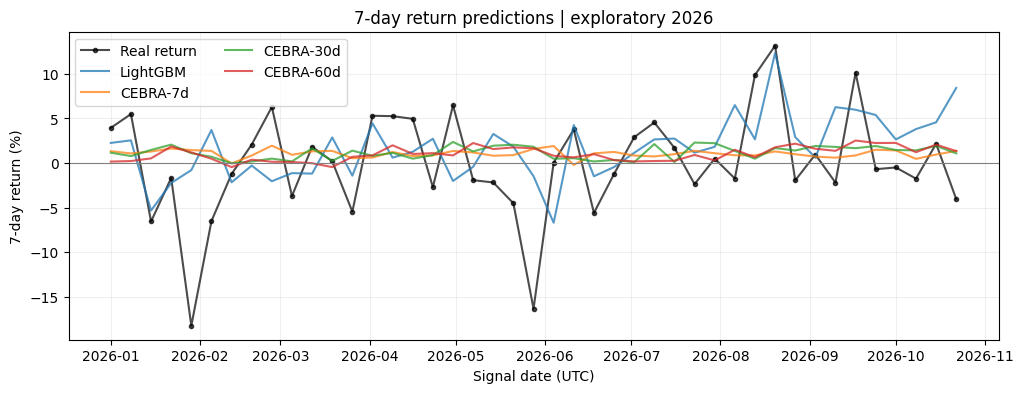

In [13]:
# NEW CELL 4 — 7-day return + direction accuracy, same weekly observations
# Interpret the 2026 results as exploratory: earlier testing already exposed this period.
def xp_metrics(indices):
    actual = xp_y[indices]
    labels = xp_clf_labels[indices]
    regression = []
    for name, pred in [('Zero forecast', np.zeros(len(xp_y))), *xp_preds.items()]:
        yhat = pred[indices]
        regression.append(dict(model=name, n=len(indices),
            MAE=mean_absolute_error(actual, yhat),
            RMSE=np.sqrt(mean_squared_error(actual, yhat)),
            R2=r2_score(actual, yhat),
            DirectionAcc=np.mean((yhat > 0) == (actual > 0))))
    classification = []
    for name, p in xp_probs.items():
        p = np.asarray(p)[indices]
        classification.append(dict(model=name, n=len(indices),
            Accuracy=accuracy_score(labels, p >= 0.5),
            Brier=brier_score_loss(labels, p),
            MeanPredictedUp=float(p.mean()), ActualUp=float(labels.mean())))
    return (pd.DataFrame(regression).set_index('model'),
            pd.DataFrame(classification).set_index('model'))

for name, ix in [('VALIDATION 2025', xp_iv), ('EXPLORATORY TEST 2026', xp_it)]:
    reg, clf = xp_metrics(ix)
    print('\n---', name, '| RETURN FORECAST ---')
    display(reg.style.format({'MAE':'{:.3%}','RMSE':'{:.3%}',
                              'R2':'{:.3f}','DirectionAcc':'{:.1%}'}))
    print('---', name, '| UP/DOWN FORECAST ---')
    display(clf.style.format({'Accuracy':'{:.1%}','Brier':'{:.3f}',
                              'MeanPredictedUp':'{:.1%}','ActualUp':'{:.1%}'}))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(xp_time[xp_it], xp_y[xp_it]*100, 'k.-', label='Real return', alpha=.7)
for name, pred in xp_preds.items():
    ax.plot(xp_time[xp_it], pred[xp_it]*100, label=name, alpha=.75)
ax.axhline(0, color='gray', lw=.8)
ax.set(title='7-day return predictions | exploratory 2026',
       xlabel='Signal date (UTC)', ylabel='7-day return (%)')
ax.legend(ncol=2); ax.grid(alpha=.2); plt.show()


Thresholds chosen on 2025 validation, never 2026:
{'LightGBM | return': 0.005, 'CEBRA-7d | return': 0.02, 'CEBRA-30d | return': 0.005, 'CEBRA-60d | return': 0.005, 'LightGBM | direction': 0.5, 'CEBRA-7d | direction': 0.6, 'CEBRA-30d | direction': 0.5, 'CEBRA-60d | direction': 0.55}

2026 exploratory backtest (43 weekly observations approximately):


,invested_weeks,orders,return_net,max_drawdown
strategy,,,,
LightGBM | direction,20,16,72.99%,-9.58%
LightGBM | return,28,14,46.66%,-9.55%
CEBRA-60d | direction,13,18,5.37%,-6.80%
Cash,0,0,0.00%,0.00%
CEBRA-7d | direction,0,0,0.00%,0.00%
CEBRA-7d | return,0,0,0.00%,0.00%
Buy & Hold BTC,43,2,-9.30%,-37.61%
CEBRA-30d | direction,40,8,-18.55%,-36.92%
CEBRA-60d | return,29,8,-23.26%,-39.05%


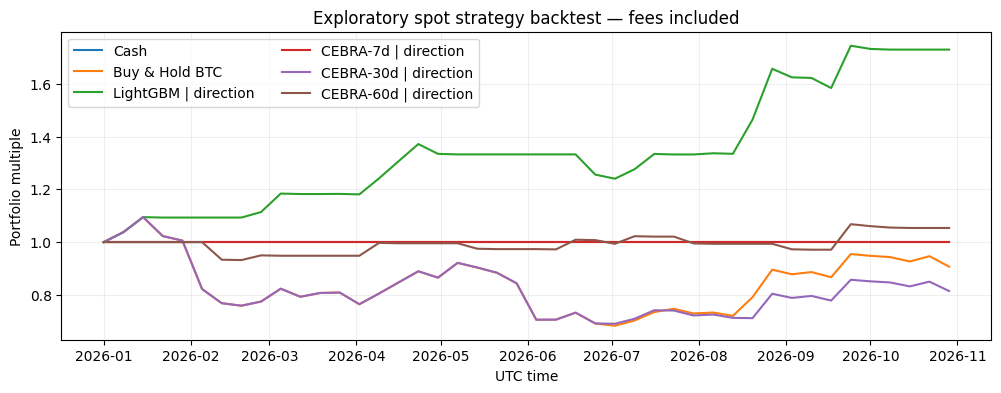

Saved two CSV reports.


In [14]:
# NEW CELL 5 — spot trading simulation; tune thresholds ONLY on 2025 validation
XP_ONE_WAY_COST = 0.0015   # illustrative fee + slippage each time position changes
XP_R_THRESHOLDS = [-0.005, 0, 0.005, 0.01, 0.02]
XP_P_THRESHOLDS = [0.45, 0.50, 0.55, 0.60]

def xp_equity(idx, pos):
    pos = np.asarray(pos, dtype=int)
    equity = [1.0]
    previous = 0
    for i, p in zip(idx, pos):
        fee = XP_ONE_WAY_COST * abs(int(p) - previous)
        equity.append(equity[-1] * (1-fee) * (1+int(p)*xp_y[i]))
        previous = int(p)
    if len(pos) and previous:
        equity[-1] *= 1-XP_ONE_WAY_COST  # exit at end of backtest
    return np.asarray(equity)

def xp_choose(model_output, thresholds, idx=xp_iv):
    return max(thresholds, key=lambda th: xp_equity(idx, (model_output[idx]>th).astype(int))[-1])

xp_positions = {
    'Cash': np.zeros(len(xp_it), dtype=int),
    'Buy & Hold BTC': np.ones(len(xp_it), dtype=int),
}
xp_selected = {}
for name, pred in xp_preds.items():
    th = xp_choose(np.asarray(pred), XP_R_THRESHOLDS)
    xp_selected[f'{name} | return'] = th
    xp_positions[f'{name} | return'] = (pred[xp_it] > th).astype(int)
for name, prob in xp_probs.items():
    th = xp_choose(np.asarray(prob), XP_P_THRESHOLDS)
    xp_selected[f'{name} | direction'] = th
    xp_positions[f'{name} | direction'] = (prob[xp_it] > th).astype(int)

xp_curves = {}
xp_report = []
for name, pos in xp_positions.items():
    curve = xp_equity(xp_it, pos)
    xp_curves[name] = curve
    dd = curve / np.maximum.accumulate(curve) - 1
    orders = int(np.abs(np.diff(np.r_[0, pos, 0])).sum())
    xp_report.append(dict(strategy=name, invested_weeks=int(pos.sum()),
                          orders=orders, return_net=curve[-1]-1,
                          max_drawdown=float(dd.min())))
print('Thresholds chosen on 2025 validation, never 2026:')
print(xp_selected)
print('\n2026 exploratory backtest (43 weekly observations approximately):')
xp_report = pd.DataFrame(xp_report).set_index('strategy')
display(xp_report.sort_values('return_net', ascending=False).style.format({
    'return_net':'{:.2%}','max_drawdown':'{:.2%}'}))

fig, ax = plt.subplots(figsize=(12, 4))
times = [xp_time[xp_it[0]]] + list(xp_end_time[xp_it])
for name in ['Cash', 'Buy & Hold BTC', 'LightGBM | direction',
             'CEBRA-7d | direction', 'CEBRA-30d | direction',
             'CEBRA-60d | direction']:
    ax.plot(times, xp_curves[name], label=name)
ax.set(title='Exploratory spot strategy backtest — fees included',
       ylabel='Portfolio multiple', xlabel='UTC time')
ax.legend(ncol=2); ax.grid(alpha=.2); plt.show()

pd.DataFrame({'signal_time':xp_time[xp_it], 'real_7d_return':xp_y[xp_it],
   **{f'prediction_{name}':p[xp_it] for name,p in xp_preds.items()},
   **{f'prob_up_{name}':p[xp_it] for name,p in xp_probs.items()},
}).to_csv('btc_extended_2026_predictions.csv', index=False)
xp_report.to_csv('btc_extended_strategy_report.csv')
print('Saved two CSV reports.')



**Part #3**

```
main focus on LightGBM




In [15]:
# CELL 1 — price-only features & chronological splits
# Run after the Binance download cell that creates `df` with columns time_utc, close.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.metrics import mean_absolute_error, accuracy_score, brier_score_loss
from IPython.display import display

LG_HORIZON = 168  # holding period in hours (7 days)
LG_FEE = 0.0015  # illustrative commission + slippage per position switch (0.15%)
LG_SEED = 42

lg_prices = (df[['time_utc', 'close']].copy()
             .drop_duplicates('time_utc')
             .sort_values('time_utc')
             .set_index('time_utc')['close']
             .asfreq('h'))
assert (lg_prices.dropna() > 0).all()
lg_log = np.log(lg_prices)
lg_ret = lg_log.diff()
lg_f = {}
for h in [1, 6, 24, 72, 168, 336, 720, 1440]:
    lg_f[f'return_{h}h'] = lg_log - lg_log.shift(h)
for h in [24, 168, 720, 1440]:
    lg_f[f'vol_{h}h'] = lg_ret.rolling(h).std()
for h in [24, 168, 720, 1440]:
    lg_f[f'mean_gap_{h}h'] = lg_log - lg_log.rolling(h).mean()
for h in [168, 720, 1440]:
    lg_f[f'drawdown_{h}h'] = lg_prices / lg_prices.rolling(h).max() - 1
lg_F = pd.DataFrame(lg_f, index=lg_prices.index)

# We observe the close at time t, place a hypothetical trade at close(t+1),
# and measure its return to close(t+169) -- exactly 168 hours of exposure.
lg_entry = lg_prices.shift(-1)
lg_exit = lg_prices.shift(-(LG_HORIZON + 1))
lg_target = lg_exit / lg_entry - 1

# Reject windows crossing missing hourly candles (no accidental bridging gaps).
lg_observed = lg_prices.notna().astype(int)
lg_hist_ok = lg_observed.rolling(1441, min_periods=1441).sum().eq(1441)
lg_future_ok = (lg_observed.iloc[::-1]
                .rolling(LG_HORIZON + 1, min_periods=LG_HORIZON + 1)
                .sum().iloc[::-1].shift(-1).eq(LG_HORIZON + 1))
lg_ok = (lg_hist_ok & lg_future_ok & lg_F.notna().all(axis=1)
         & lg_target.notna())
lg_X = lg_F.loc[lg_ok].copy()
lg_y = lg_target.loc[lg_ok].to_numpy(dtype=float)
lg_t = lg_X.index
lg_label_end = lg_t + pd.Timedelta(hours=LG_HORIZON + 1)

train_cut = pd.Timestamp('2025-01-01', tz='UTC')
mid_cut = pd.Timestamp('2025-07-01', tz='UTC')
test_cut = pd.Timestamp('2026-01-01', tz='UTC')
lg_train = np.asarray(lg_label_end < train_cut)
lg_v1 = np.asarray((lg_t >= train_cut) & (lg_label_end < mid_cut))
lg_v2 = np.asarray((lg_t >= mid_cut) & (lg_label_end < test_cut))
lg_test = np.asarray(lg_t >= test_cut)

# Train using every 6th eligible hour to limit duplicated overlapping labels.
lg_train_ids = np.flatnonzero(lg_train)[::6]
assert len(lg_train_ids) > 100 and lg_v1.sum() > 100 and lg_v2.sum() > 100 and lg_test.sum() > 100

def lg_weekly(mask):
    positions = np.flatnonzero(mask)
    chosen, last_t = [], None
    for j in positions:
        if last_t is None or lg_t[j] >= last_t + pd.Timedelta(hours=LG_HORIZON):
            chosen.append(j)
            last_t = lg_t[j]
    return np.asarray(chosen, dtype=int)

lg_i1 = lg_weekly(lg_v1)  # 2025 H1: select decision threshold
lg_i2 = lg_weekly(lg_v2)  # 2025 H2: select the model
lg_it = lg_weekly(lg_test)  # 2026: exploratory evaluation only

lg_feature_sets = {
    'Momentum': [c for c in lg_X if c.startswith('return_')],
    'Momentum+Vol': [c for c in lg_X if c.startswith(('return_', 'vol_'))],
    'FullPrice': lg_X.columns.tolist(),
}
print(f'Hourly candles available: {lg_prices.notna().sum():,}')
print(f'Examples for model training (every 6h): {len(lg_train_ids):,}')
print(f'Weekly H1 / H2 / 2026: {len(lg_i1)} / {len(lg_i2)} / {len(lg_it)}')
print(f'All features: {lg_X.shape[1]} | No news, no volume, no CEBRA')

Hourly candles available: 42,359
Examples for model training (every 6h): 3,848
Weekly H1 / H2 / 2026: 25 / 26 / 43
All features: 19 | No news, no volume, no CEBRA


In [16]:
# CELL 2 — LightGBM model experiments: 3 feature groups x 2 model sizes x 2 targets
from itertools import product

lg_configs = {
    'Small': dict(n_estimators=250, learning_rate=0.03, num_leaves=7,
                  max_depth=3, min_child_samples=180, reg_lambda=5.0,
                  colsample_bytree=0.85, subsample=0.85, subsample_freq=1),
    'Medium': dict(n_estimators=350, learning_rate=0.03, num_leaves=15,
                   max_depth=5, min_child_samples=90, reg_lambda=3.0,
                   colsample_bytree=0.85, subsample=0.85, subsample_freq=1),
}
lg_models, lg_forecasts = {}, {}
lg_binary = (lg_y > 0).astype(int)

for group, size, goal in product(lg_feature_sets, lg_configs, ['Direction', 'Return']):
    cols = lg_feature_sets[group]
    label = f'{group} | {size} | {goal}'
    params = dict(lg_configs[size], random_state=LG_SEED,
                  n_jobs=-1, verbosity=-1)
    model = (LGBMClassifier(**params) if goal == 'Direction'
             else LGBMRegressor(**params))
    yfit = lg_binary[lg_train_ids] if goal == 'Direction' else lg_y[lg_train_ids]
    model.fit(lg_X.iloc[lg_train_ids][cols], yfit)
    lg_models[label] = model
    # Keep all predictions so later evaluation uses identical weekly observations.
    pred = (model.predict_proba(lg_X[cols])[:, 1] if goal == 'Direction'
            else model.predict(lg_X[cols]))
    lg_forecasts[label] = np.asarray(pred, dtype=float)
    print(f'Trained: {label}')
print(f'\nCompleted {len(lg_forecasts)} LightGBM variants.')

Trained: Momentum | Small | Direction
Trained: Momentum | Small | Return
Trained: Momentum | Medium | Direction
Trained: Momentum | Medium | Return
Trained: Momentum+Vol | Small | Direction
Trained: Momentum+Vol | Small | Return
Trained: Momentum+Vol | Medium | Direction
Trained: Momentum+Vol | Medium | Return
Trained: FullPrice | Small | Direction
Trained: FullPrice | Small | Return
Trained: FullPrice | Medium | Direction
Trained: FullPrice | Medium | Return

Completed 12 LightGBM variants.


In [17]:
# CELL 3 — real spot-style weekly backtest with position-switching costs
# CASH / BTC only, no leverage and no short positions.
def lg_backtest(ids, positions, fee=LG_FEE):
    positions = np.asarray(positions, dtype=int)
    if len(ids) != len(positions):
        raise ValueError('Weekly indexes and positions must have equal length')
    if not np.isin(positions, [0, 1]).all():
        raise ValueError('Spot positions must be 0 or 1')
    wealth = [1.0]
    last = 0
    for j, pos in zip(ids, positions):
        change_cost = fee * abs(pos - last)
        wealth.append(wealth[-1] * (1 - change_cost) * (1 + pos * lg_y[j]))
        last = pos
    if len(positions) and last == 1:
        wealth[-1] *= (1 - fee)  # liquidate at the final close
    wealth = np.asarray(wealth)
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    return dict(net_return=float(wealth[-1] - 1),
                max_drawdown=float(drawdown.min()),
                invested_weeks=int(positions.sum()),
                trades=int(np.abs(np.diff(np.r_[0, positions, 0])).sum()),
                equity=wealth)

lg_thresholds = {
    'Direction': [0.50, 0.55, 0.60],   # P(up) > threshold
    'Return': [0.0, 0.005, 0.01],     # predicted weekly return > threshold
}

def lg_positions(name, ids, threshold):
    return (lg_forecasts[name][ids] > threshold).astype(int)

# Select a threshold using ONLY Jan–Jun 2025. Require at least three
# invested weeks when possible; otherwise expose the low-activity case.
lg_choices = {}
for name in lg_forecasts:
    target = name.split(' | ')[-1]
    candidates = []
    for th in lg_thresholds[target]:
        result = lg_backtest(lg_i1, lg_positions(name, lg_i1, th))
        candidates.append((th, result))
    eligible = [(th, r) for th, r in candidates if r['invested_weeks'] >= 3]
    group = eligible if eligible else candidates
    lg_choices[name] = max(group, key=lambda item: item[1]['net_return'])[0]

# Model selection ONLY with Jul–Dec 2025 (threshold frozen).
lg_rank = []
for name, threshold in lg_choices.items():
    score1 = lg_backtest(lg_i1, lg_positions(name, lg_i1, threshold))
    score2 = lg_backtest(lg_i2, lg_positions(name, lg_i2, threshold))
    lg_rank.append(dict(model=name, threshold=threshold,
                        h1_return=score1['net_return'],
                        h2_return=score2['net_return'],
                        h2_max_dd=score2['max_drawdown'],
                        h2_invested=score2['invested_weeks'],
                        h2_trades=score2['trades']))
lg_rank = pd.DataFrame(lg_rank)
lg_ok_rank = lg_rank[lg_rank.h2_invested >= 3]
lg_candidates = lg_ok_rank if len(lg_ok_rank) else lg_rank
lg_winner = (lg_candidates.sort_values(['h2_return', 'h2_max_dd'],
                                       ascending=[False, False])
             .iloc[0]['model'])
print('Selected using H1 2025 thresholds and H2 2025 ranking:', lg_winner)
print('Chosen threshold:', lg_choices[lg_winner])
display(lg_rank.sort_values('h2_return', ascending=False)
        .style.format({'h1_return':'{:.2%}','h2_return':'{:.2%}',
                       'h2_max_dd':'{:.2%}','threshold':'{:.3f}'}))

Selected using H1 2025 thresholds and H2 2025 ranking: Momentum | Medium | Return
Chosen threshold: 0.005


,model,threshold,h1_return,h2_return,h2_max_dd,h2_invested,h2_trades
3,Momentum | Medium | Return,0.005,30.60%,-10.72%,-24.71%,13,14
7,Momentum+Vol | Medium | Return,0.010,12.33%,-11.55%,-25.23%,13,10
0,Momentum | Small | Direction,0.600,15.60%,-12.04%,-17.57%,4,6
2,Momentum | Medium | Direction,0.550,15.32%,-14.01%,-25.18%,11,12
1,Momentum | Small | Return,0.010,19.05%,-17.60%,-19.98%,7,12
6,Momentum+Vol | Medium | Direction,0.550,3.07%,-19.01%,-27.33%,11,6
8,FullPrice | Small | Direction,0.500,5.81%,-19.62%,-31.42%,15,6
11,FullPrice | Medium | Return,0.000,-0.99%,-20.28%,-30.22%,15,12
5,Momentum+Vol | Small | Return,0.005,16.67%,-20.67%,-30.22%,19,14
9,FullPrice | Small | Return,0.000,7.35%,-22.10%,-30.73%,20,8


In [18]:
# CELL 4 — report every strategy on 2026, but DO NOT choose the winner on 2026
lg_test_rows, lg_curves = [], {}
for name in lg_forecasts:
    result = lg_backtest(lg_it, lg_positions(name, lg_it, lg_choices[name]))
    lg_curves[name] = result.pop('equity')
    lg_test_rows.append(dict(model=name, threshold=lg_choices[name], **result))
for name, pos in [('Cash', np.zeros(len(lg_it), dtype=int)),
                  ('Buy & Hold', np.ones(len(lg_it), dtype=int))]:
    result = lg_backtest(lg_it, pos)
    lg_curves[name] = result.pop('equity')
    lg_test_rows.append(dict(model=name, threshold=np.nan, **result))
lg_test_report = pd.DataFrame(lg_test_rows)
print('2026 EXPLORATORY results (previously seen, NOT a pristine holdout):')
display(lg_test_report.sort_values('net_return', ascending=False)
        .style.format({'net_return':'{:.2%}', 'max_drawdown':'{:.2%}',
                       'threshold':'{:.3f}'}))

win_result = lg_test_report.loc[lg_test_report.model == lg_winner].iloc[0]
print(f"\nH2-2025-selected winner: {lg_winner}")
print(f"2026 exploratory net return: {win_result['net_return']:.2%} | "
      f"max drawdown: {win_result['max_drawdown']:.2%} | "
      f"invested: {int(win_result['invested_weeks'])}/{len(lg_it)} weeks")
print('The highest 2026 row is descriptive only; do not select or tune from it.')

lg_val_comp = []
for name, pos in [('Cash', np.zeros(len(lg_i2), dtype=int)),
                  ('Buy & Hold', np.ones(len(lg_i2), dtype=int)),
                  (lg_winner, lg_positions(lg_winner, lg_i2, lg_choices[lg_winner]))]:
    r = lg_backtest(lg_i2, pos)
    lg_val_comp.append(dict(model=name, h2_2025_net_return=r['net_return'],
                            h2_2025_max_drawdown=r['max_drawdown']))
print('\nModel-selection period vs benchmarks (Jul–Dec 2025):')
display(pd.DataFrame(lg_val_comp).style.format({
    'h2_2025_net_return':'{:.2%}', 'h2_2025_max_drawdown':'{:.2%}'}))

2026 EXPLORATORY results (previously seen, NOT a pristine holdout):


,model,threshold,net_return,max_drawdown,invested_weeks,trades
3,Momentum | Medium | Return,0.005,63.78%,-5.12%,24,18
6,Momentum+Vol | Medium | Direction,0.550,49.09%,-11.27%,26,10
0,Momentum | Small | Direction,0.600,41.03%,-2.64%,16,16
7,Momentum+Vol | Medium | Return,0.010,38.92%,-11.29%,30,14
8,FullPrice | Small | Direction,0.500,38.17%,-9.66%,26,10
4,Momentum+Vol | Small | Direction,0.500,31.38%,-13.01%,26,12
1,Momentum | Small | Return,0.010,26.39%,-6.99%,20,24
10,FullPrice | Medium | Direction,0.500,25.66%,-19.58%,29,10
2,Momentum | Medium | Direction,0.550,20.80%,-9.77%,22,16
11,FullPrice | Medium | Return,0.000,18.12%,-17.76%,32,14



H2-2025-selected winner: Momentum | Medium | Return
2026 exploratory net return: 63.78% | max drawdown: -5.12% | invested: 24/43 weeks
The highest 2026 row is descriptive only; do not select or tune from it.

Model-selection period vs benchmarks (Jul–Dec 2025):


,model,h2_2025_net_return,h2_2025_max_drawdown
0,Cash,0.00%,0.00%
1,Buy & Hold,-18.82%,-31.12%
2,Momentum | Medium | Return,-10.72%,-24.71%


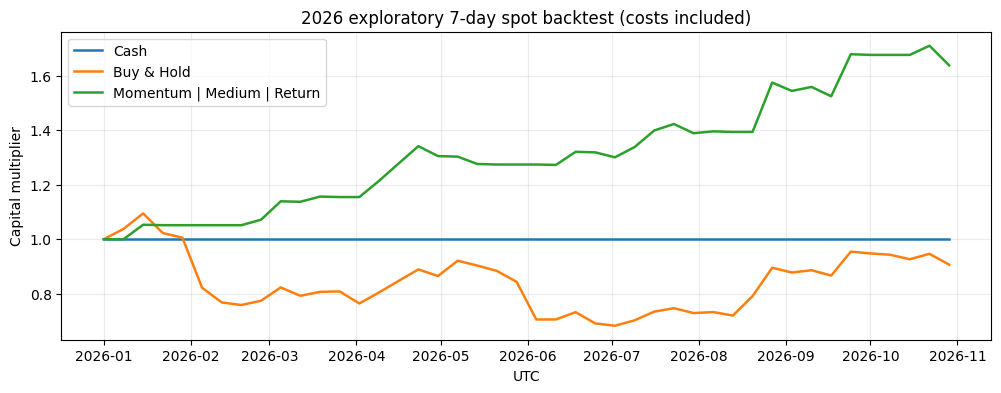

Winner: Direction accuracy: 69.77% | Weekly return MAE: 0.0381


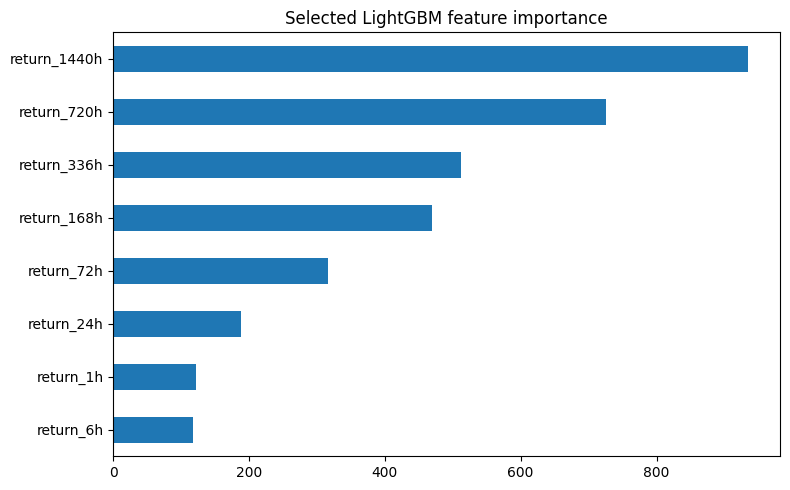

Saved:
 - btc_lightgbm_2026_exploratory_leaderboard.csv
 - btc_lightgbm_2025_validation_ranking.csv
 - btc_lightgbm_winner_2026_weekly_signals.csv


In [19]:
# CELL 5 — equity plots, directional accuracy, feature importance, export results
fig, ax = plt.subplots(figsize=(12, 4))
lg_plot_time = [lg_t[lg_it[0]]] + [lg_t[j] + pd.Timedelta(hours=LG_HORIZON + 1)
                                      for j in lg_it]
for name in ['Cash', 'Buy & Hold', lg_winner]:
    ax.plot(lg_plot_time, lg_curves[name], label=name, lw=1.8)
ax.set(xlabel='UTC', ylabel='Capital multiplier',
       title='2026 exploratory 7-day spot backtest (costs included)')
ax.legend(); ax.grid(alpha=0.25); plt.show()

p = lg_forecasts[lg_winner][lg_it]
actual_up = (lg_y[lg_it] > 0).astype(int)
if lg_winner.endswith('Direction'):
    lg_direction = (p > 0.5).astype(int)
    print('Winner: Direction accuracy:', f'{accuracy_score(actual_up, lg_direction):.2%}',
          '| Brier:', f'{brier_score_loss(actual_up, p):.4f}')
else:
    lg_direction = (p > 0).astype(int)
    print('Winner: Direction accuracy:', f'{accuracy_score(actual_up, lg_direction):.2%}',
          '| Weekly return MAE:', f'{mean_absolute_error(lg_y[lg_it], p):.4f}')

feature_names = lg_feature_sets[lg_winner.split(' | ')[0]]
feat_imp = pd.Series(lg_models[lg_winner].feature_importances_, index=feature_names)
feat_imp.sort_values().tail(15).plot.barh(figsize=(8, 5), title='Selected LightGBM feature importance')
plt.tight_layout(); plt.show()

lg_report_path = 'btc_lightgbm_2026_exploratory_leaderboard.csv'
lg_rank_path = 'btc_lightgbm_2025_validation_ranking.csv'
lg_trades_path = 'btc_lightgbm_winner_2026_weekly_signals.csv'
lg_test_report.to_csv(lg_report_path, index=False)
lg_rank.to_csv(lg_rank_path, index=False)
pd.DataFrame({
    'signal_utc': lg_t[lg_it],
    'actual_7d_return': lg_y[lg_it],
    'model_output': p,
    'position_BTC_1_CASH_0': lg_positions(lg_winner, lg_it, lg_choices[lg_winner]),
}).to_csv(lg_trades_path, index=False)
print('Saved:', lg_report_path, lg_rank_path, lg_trades_path, sep='\n - ')
print('WARNING: no live performance is established; 2026 was viewed in earlier experiments.')